In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, confusion_matrix,
    classification_report
)

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("student_placement_dataset.csv")

print("Dataset Shape:")
print(df.shape)

print("\nFirst Five Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe(include="all"))

Saving student_placement_dataset.csv to student_placement_dataset.csv
Dataset Shape:
(1200, 18)

First Five Rows:
  Student_ID  Gender      Branch  SSC_Percentage  HSC_Percentage  CGPA  \
0    STU1000    Male  Mechanical            85.2            75.9  7.17   
1    STU1001    Male          IT            85.0            72.7  6.41   
2    STU1002  Female       Civil            79.7            85.1  7.46   
3    STU1003  Female  Mechanical            81.6            67.0  4.51   
4    STU1004    Male    Computer            70.5            78.8  8.19   

   Active_Backlogs  Internships  Projects  Certifications  Aptitude_Score  \
0                2          0.0         3               1            65.0   
1                0          0.0         3               2            69.0   
2                1          1.0         2               0            72.0   
3                1          1.0         0               3            63.0   
4                0          0.0         2               

In [2]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nUnique Values in Each Column:")
for column in df.columns:
    print(column, ":", df[column].nunique())
    if df[column].nunique() <= 10:
        print(df[column].unique())

Column Names:
['Student_ID', 'Gender', 'Branch', 'SSC_Percentage', 'HSC_Percentage', 'CGPA', 'Active_Backlogs', 'Internships', 'Projects', 'Certifications', 'Aptitude_Score', 'Communication_Skill', 'Coding_Hours_Per_Week', 'City_Tier', 'Hostel_Resident', 'Family_Income_LPA', 'Extracurricular', 'Placed']

Data Types:
Student_ID                object
Gender                    object
Branch                    object
SSC_Percentage           float64
HSC_Percentage           float64
CGPA                     float64
Active_Backlogs            int64
Internships              float64
Projects                   int64
Certifications             int64
Aptitude_Score           float64
Communication_Skill       object
Coding_Hours_Per_Week    float64
City_Tier                 object
Hostel_Resident           object
Family_Income_LPA        float64
Extracurricular           object
Placed                    object
dtype: object

Unique Values in Each Column:
Student_ID : 1200
Gender : 2
['Male' 'Femal

In [3]:
# Remove Student_ID
df = df.drop(columns=["Student_ID"])

# Separate features and target
X = df.drop(columns=["Placed"])
y = df["Placed"]

# Handle missing values
numeric_columns = X.select_dtypes(include=np.number).columns
categorical_columns = X.select_dtypes(include="object").columns

for column in numeric_columns:
    X[column] = X[column].fillna(X[column].median())

for column in categorical_columns:
    X[column] = X[column].fillna(X[column].mode()[0])

# Encode categorical features
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Encode target variable
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Preprocessed Features:")
print(X.head())

print("\nTarget Values:")
print(np.unique(y))

print("\nMissing Values:")
print(X.isnull().sum().sum())

Preprocessed Features:
   SSC_Percentage  HSC_Percentage  CGPA  Active_Backlogs  Internships  \
0            85.2            75.9  7.17                2          0.0   
1            85.0            72.7  6.41                0          0.0   
2            79.7            85.1  7.46                1          1.0   
3            81.6            67.0  4.51                1          1.0   
4            70.5            78.8  8.19                0          0.0   

   Projects  Certifications  Aptitude_Score  Coding_Hours_Per_Week  \
0         3               1            65.0                    1.8   
1         3               2            69.0                    2.5   
2         2               0            72.0                    7.3   
3         0               3            63.0                   20.3   
4         2               0            62.0                    3.5   

   Family_Income_LPA  ...  Branch_E&TC  Branch_Electrical  Branch_IT  \
0               7.98  ...            0       

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (960, 22)
Testing Data Shape: (240, 22)

Training Target Shape: (960,)
Testing Target Shape: (240,)


In [5]:
svm_model = SVC(probability=True, random_state=42)

svm_model.fit(X_train_scaled, y_train)

svm_predictions = svm_model.predict(X_test_scaled)
svm_probabilities = svm_model.predict_proba(X_test_scaled)

print("SVM Classification Results")
print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Precision:", precision_score(y_test, svm_predictions, zero_division=0))
print("Recall:", recall_score(y_test, svm_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, svm_predictions, zero_division=0))
print("Log Loss:", log_loss(y_test, svm_probabilities))

SVM Classification Results
Accuracy: 0.7666666666666667
Precision: 0.7474747474747475
Recall: 0.7047619047619048
F1 Score: 0.7254901960784313
Log Loss: 0.47758784886108274


In [6]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)
dt_probabilities = dt_model.predict_proba(X_test)

print("Decision Tree Classification Results")
print("Accuracy:", accuracy_score(y_test, dt_predictions))
print("Precision:", precision_score(y_test, dt_predictions, zero_division=0))
print("Recall:", recall_score(y_test, dt_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, dt_predictions, zero_division=0))
print("Log Loss:", log_loss(y_test, dt_probabilities))

Decision Tree Classification Results
Accuracy: 0.6125
Precision: 0.5625
Recall: 0.5142857142857142
F1 Score: 0.5373134328358209
Log Loss: 13.966915688282898


In [7]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)
knn_probabilities = knn_model.predict_proba(X_test_scaled)

print("KNN Classification Results")
print("Accuracy:", accuracy_score(y_test, knn_predictions))
print("Precision:", precision_score(y_test, knn_predictions, zero_division=0))
print("Recall:", recall_score(y_test, knn_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, knn_predictions, zero_division=0))
print("Log Loss:", log_loss(y_test, knn_probabilities))

KNN Classification Results
Accuracy: 0.6791666666666667
Precision: 0.6272727272727273
Recall: 0.6571428571428571
F1 Score: 0.641860465116279
Log Loss: 1.875244444925969


In [8]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

nb_predictions = nb_model.predict(X_test_scaled)
nb_probabilities = nb_model.predict_proba(X_test_scaled)

print("Naive Bayes Classification Results")
print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Precision:", precision_score(y_test, nb_predictions, zero_division=0))
print("Recall:", recall_score(y_test, nb_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, nb_predictions, zero_division=0))
print("Log Loss:", log_loss(y_test, nb_probabilities))

Naive Bayes Classification Results
Accuracy: 0.7666666666666667
Precision: 0.7289719626168224
Recall: 0.7428571428571429
F1 Score: 0.7358490566037735
Log Loss: 0.5223771249991939


In [9]:
results = {
    "Model": ["SVM", "Decision Tree", "KNN", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, svm_predictions),
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, nb_predictions)
    ],
    "Precision": [
        precision_score(y_test, svm_predictions, zero_division=0),
        precision_score(y_test, dt_predictions, zero_division=0),
        precision_score(y_test, knn_predictions, zero_division=0),
        precision_score(y_test, nb_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, svm_predictions, zero_division=0),
        recall_score(y_test, dt_predictions, zero_division=0),
        recall_score(y_test, knn_predictions, zero_division=0),
        recall_score(y_test, nb_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, svm_predictions, zero_division=0),
        f1_score(y_test, dt_predictions, zero_division=0),
        f1_score(y_test, knn_predictions, zero_division=0),
        f1_score(y_test, nb_predictions, zero_division=0)
    ],
    "Log Loss": [
        log_loss(y_test, svm_probabilities),
        log_loss(y_test, dt_probabilities),
        log_loss(y_test, knn_probabilities),
        log_loss(y_test, nb_probabilities)
    ]
}

results_df = pd.DataFrame(results)

print("Model Comparison:")
print(results_df)

print("\nBest Model Based on Accuracy:")
print(results_df.loc[results_df["Accuracy"].idxmax()])

Model Comparison:
           Model  Accuracy  Precision    Recall  F1 Score   Log Loss
0            SVM  0.766667   0.747475  0.704762  0.725490   0.477588
1  Decision Tree  0.612500   0.562500  0.514286  0.537313  13.966916
2            KNN  0.679167   0.627273  0.657143  0.641860   1.875244
3    Naive Bayes  0.766667   0.728972  0.742857  0.735849   0.522377

Best Model Based on Accuracy:
Model             SVM
Accuracy     0.766667
Precision    0.747475
Recall       0.704762
F1 Score      0.72549
Log Loss     0.477588
Name: 0, dtype: object



 SVM
[[110  25]
 [ 31  74]]


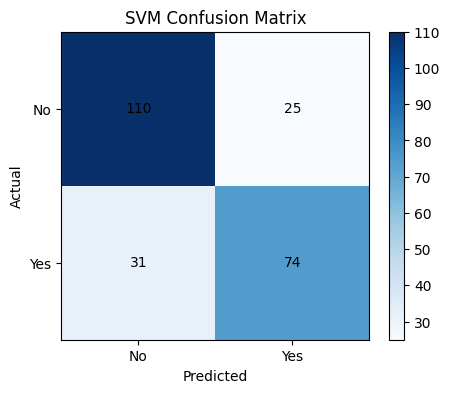


 Decision Tree
[[93 42]
 [51 54]]


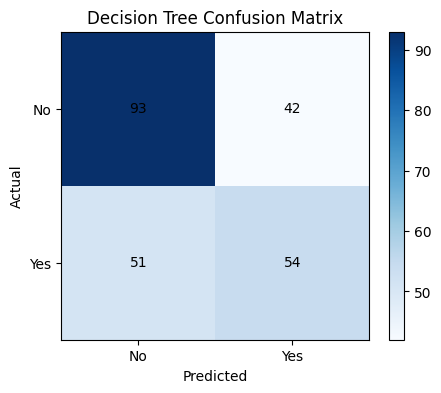


 KNN
[[94 41]
 [36 69]]


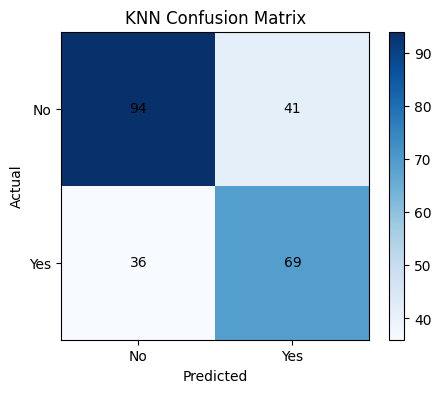


 Naive Bayes
[[106  29]
 [ 27  78]]


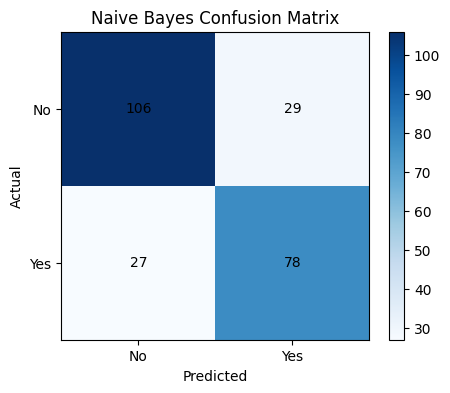

In [10]:
models = {
    "SVM": svm_predictions,
    "Decision Tree": dt_predictions,
    "KNN": knn_predictions,
    "Naive Bayes": nb_predictions
}

for name, predictions in models.items():
    print("\n", name)
    cm = confusion_matrix(y_test, predictions)
    print(cm)

    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks([0, 1], label_encoder.classes_)
    plt.yticks([0, 1], label_encoder.classes_)

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.colorbar()
    plt.show()

In [11]:
print("SVM Classification Report:")
print(classification_report(y_test, svm_predictions, target_names=label_encoder.classes_))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_predictions, target_names=label_encoder.classes_))

print("\nKNN Classification Report:")
print(classification_report(y_test, knn_predictions, target_names=label_encoder.classes_))

print("\nNaive Bayes Classification Report:")
print(classification_report(y_test, nb_predictions, target_names=label_encoder.classes_))

SVM Classification Report:
              precision    recall  f1-score   support

          No       0.78      0.81      0.80       135
         Yes       0.75      0.70      0.73       105

    accuracy                           0.77       240
   macro avg       0.76      0.76      0.76       240
weighted avg       0.77      0.77      0.77       240


Decision Tree Classification Report:
              precision    recall  f1-score   support

          No       0.65      0.69      0.67       135
         Yes       0.56      0.51      0.54       105

    accuracy                           0.61       240
   macro avg       0.60      0.60      0.60       240
weighted avg       0.61      0.61      0.61       240


KNN Classification Report:
              precision    recall  f1-score   support

          No       0.72      0.70      0.71       135
         Yes       0.63      0.66      0.64       105

    accuracy                           0.68       240
   macro avg       0.68      0.68  